### Strategic thinking Online retail CA2

In [11]:
import pandas as pd
df = pd.read_excel("Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [12]:
df.shape

(541909, 8)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [14]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [15]:
print("Negative or zero quantities:",(df["Quantity"] <= 0).sum())
print("Zero or negative prices:",(df["UnitPrice"] <= 0).sum())

Negative or zero quantities: 10624
Zero or negative prices: 2517


In [16]:
df_clean = df.copy()

df_clean = df_clean.dropna(subset=["Description"])

df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))

Original rows: 541909
Cleaned rows: 530104


In [17]:
print(df_clean.info())
print(df_clean.describe())

<class 'pandas.core.frame.DataFrame'>
Index: 530104 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    530104 non-null  object        
 1   StockCode    530104 non-null  object        
 2   Description  530104 non-null  object        
 3   Quantity     530104 non-null  int64         
 4   InvoiceDate  530104 non-null  datetime64[ns]
 5   UnitPrice    530104 non-null  float64       
 6   CustomerID   397884 non-null  float64       
 7   Country      530104 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 36.4+ MB
None
            Quantity                    InvoiceDate      UnitPrice  \
count  530104.000000                         530104  530104.000000   
mean       10.542037  2011-07-04 20:16:05.225087744       3.907625   
min         1.000000            2010-12-01 08:26:00       0.001000   
25%         1.000000        

In [18]:
df_clean["TotalSales"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

daily_sales = (
    df_clean.groupby(
        df_clean["InvoiceDate"].dt.date
    )["TotalSales"].sum()
)

daily_sales.head()

InvoiceDate
2010-12-01    58960.79
2010-12-02    47748.38
2010-12-03    46943.71
2010-12-05    31774.95
2010-12-06    54830.46
Name: TotalSales, dtype: float64

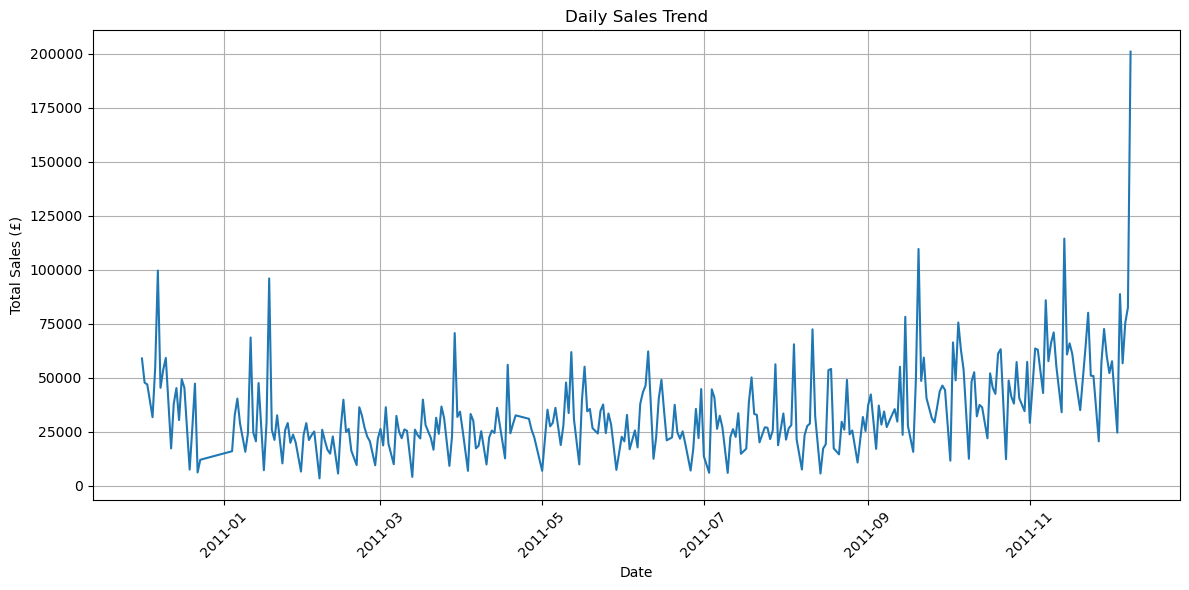

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(daily_sales.index, daily_sales.values)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales (£)")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [20]:
df_clean["TotalSales"].describe()

count    530104.000000
mean         20.121871
std         270.356743
min           0.001000
25%           3.750000
50%           9.900000
75%          17.700000
max      168469.600000
Name: TotalSales, dtype: float64

In [21]:
# Check missing values after cleaning
print(df_clean.isnull().sum())

# Check duplicate records
print("Duplicate rows:", df_clean.duplicated().sum())

# Check cancelled invoices
print(
    "Cancelled invoices:",
    df_clean["InvoiceNo"].astype(str).str.startswith("C").sum()
)

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132220
Country             0
TotalSales          0
dtype: int64
Duplicate rows: 5226
Cancelled invoices: 0


In [22]:
# Remove duplicate records
df_clean = df_clean.drop_duplicates().copy()

# Check remaining duplicates
print("Remaining duplicates:", df_clean.duplicated().sum())

# Check dataset size
print("Dataset shape:", df_clean.shape)

Remaining duplicates: 0
Dataset shape: (524878, 9)


Data Cleaning – Duplicate Records

The dataset contained 5,226 duplicate records. These duplicates were removed using the drop_duplicates() function to reduce potential double-counting in the sales analysis.

After removing duplicates, the dataset contained 524,878 rows and 9 columns, with no remaining exact duplicates.

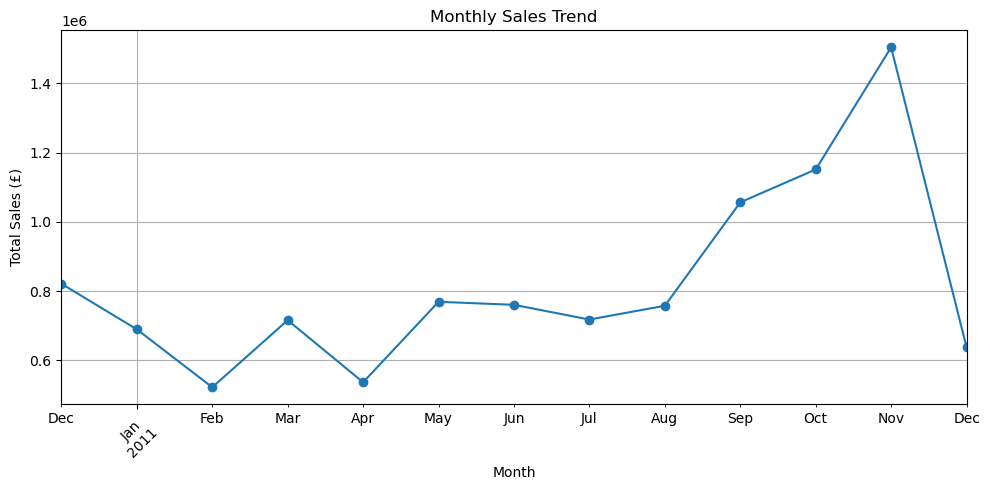

In [23]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert InvoiceDate to datetime
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Calculate monthly sales
monthly_sales = (
    df_clean.groupby(
        df_clean["InvoiceDate"].dt.to_period("M")
    )["TotalSales"].sum()
)

# Plot monthly sales trend
plt.figure(figsize=(10, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


### Monthly Sales Trend Analysis

The line chart illustrates monthly sales trends from December 2010 to December 2011. Sales increased significantly between September and November 2011, reaching a peak of approximately £1.5 million in November. February 2011 recorded the lowest sales among the complete months. This pattern suggests a possible seasonal increase in demand towards the end of the year. December 2011 contains incomplete monthly data and should not be directly compared with full months.

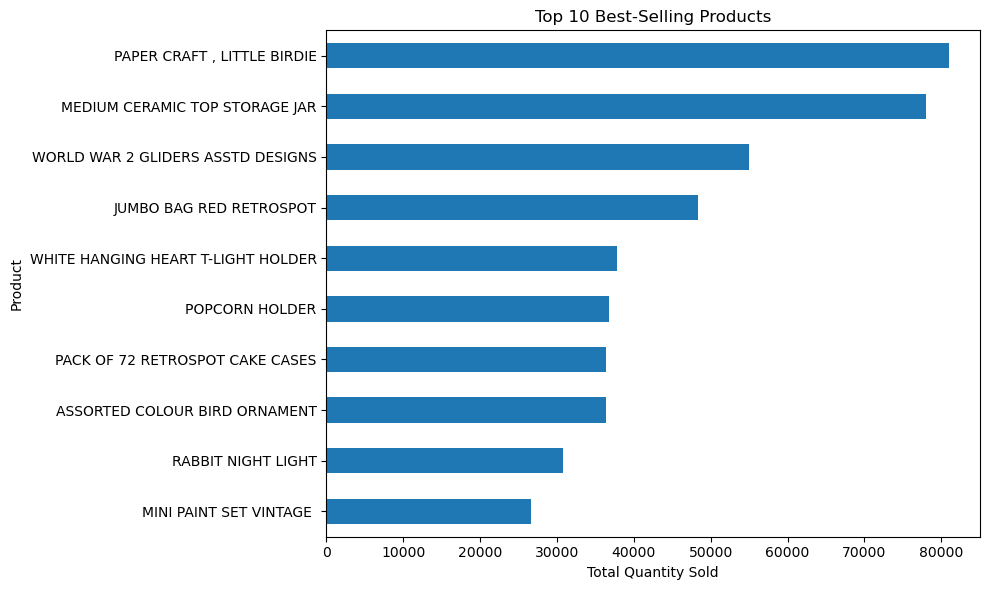

In [24]:

# Top 10 best-selling products by quantity
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Plot top 10 products
plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


### Top 10 Best-Selling Products Analysis

The bar chart shows the ten best-selling products based on total quantity sold. PAPER CRAFT, LITTLE BIRDIE had the highest sales volume, followed by MEDIUM CERAMIC TOP STORAGE JAR and WORLD WAR 2 GLIDERS ASSTD DESIGNS. These results identify products with high sales volumes and may help businesses make inventory management and stock planning decisions.

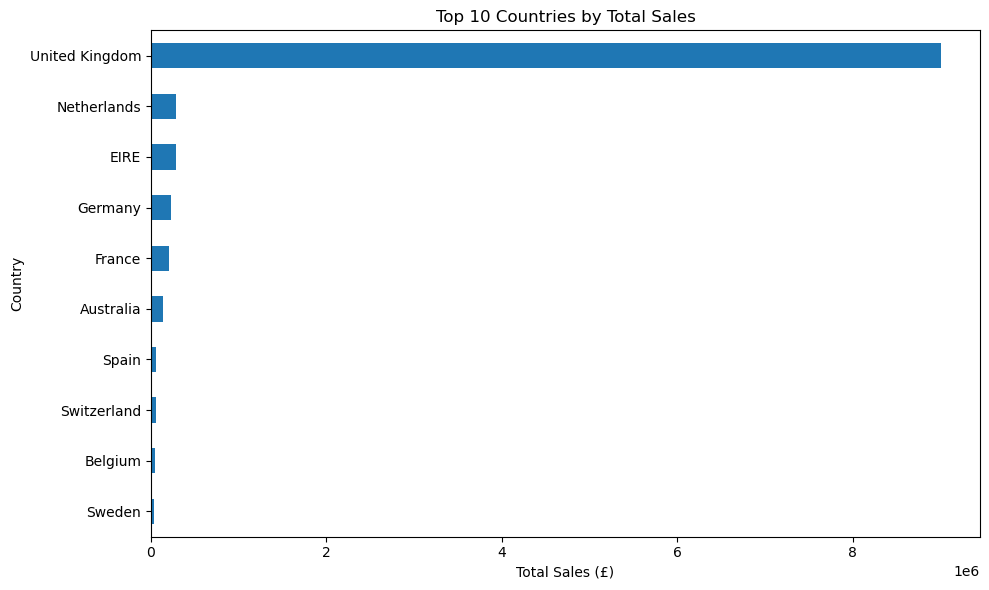

In [26]:

# Calculate total sales by country
sales_by_country = (
    df_clean.groupby("Country")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Plot top 10 countries by sales
plt.figure(figsize=(10, 6))
sales_by_country.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Total Sales")
plt.xlabel("Total Sales (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


### Sales by Country Analysis

The bar chart illustrates the top ten countries by total sales revenue. The United Kingdom generated the highest sales, significantly exceeding all other countries. The Netherlands and Ireland (EIRE) ranked second and third, respectively. These findings indicate a strong dependence on the UK market. The business could explore opportunities to expand international sales and reduce its reliance on a single market.

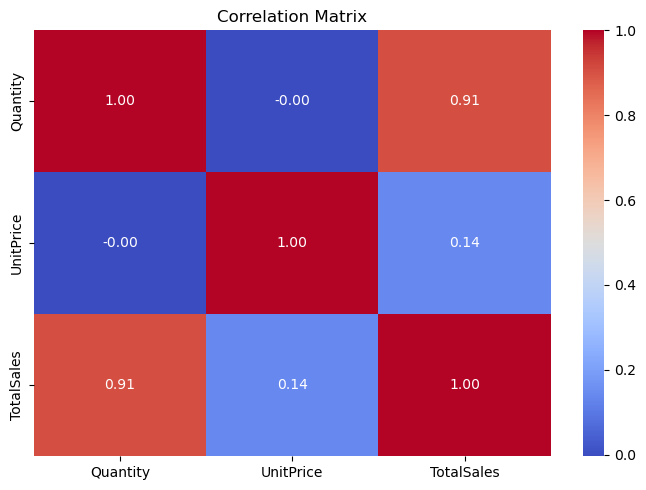

In [27]:

import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation matrix
correlation = df_clean[
    ["Quantity", "UnitPrice", "TotalSales"]
].corr()

# Plot correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


### Correlation Analysis

The correlation matrix shows a strong positive relationship between Quantity and TotalSales (r = 0.91). UnitPrice has a weak positive correlation with TotalSales (r = 0.14), while Quantity and UnitPrice show almost no linear relationship (r ≈ 0.00). Since TotalSales is calculated by multiplying Quantity and UnitPrice, these relationships should be interpreted carefully and do not establish causation.